In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Time series modeling
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Evaluation metrics
from sklearn.metrics import mean_squared_error
from math import sqrt

# To ignore warnings
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Load datasets (download from Kaggle and place the CSVs in the data/ folder — see README)
orders = pd.read_csv("data/olist_orders_dataset.csv")
order_items = pd.read_csv("data/olist_order_items_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")
category_translation = pd.read_csv("data/product_category_name_translation.csv")

In [3]:
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Category Translation:", category_translation.shape)

Orders: (99441, 8)
Order Items: (112650, 7)
Products: (32951, 9)
Category Translation: (71, 2)


In [4]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

In [5]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [7]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

## Merge Orders + Order Items

In [8]:
data = pd.merge(order_items, orders[['order_id','order_purchase_timestamp']], 
                on='order_id', how='left')

data.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51


## Merge with Products Dataset

In [9]:
data = pd.merge(data, products[['product_id','product_category_name']], 
                on='product_id', how='left')

data.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,ferramentas_jardim


## Merge Category Translation Table

In [10]:
data = pd.merge(data, category_translation,
                on='product_category_name',
                how='left')

data.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,ferramentas_jardim,garden_tools


## Check the Merged Dataset

In [11]:
data.shape
data.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'order_purchase_timestamp', 'product_category_name',
       'product_category_name_english'],
      dtype='object')

In [12]:
data = data[['order_purchase_timestamp',
             'price',
             'product_category_name_english']]

In [13]:
data.head()
data.columns

Index(['order_purchase_timestamp', 'price', 'product_category_name_english'], dtype='object')

In [14]:
data.columns

Index(['order_purchase_timestamp', 'price', 'product_category_name_english'], dtype='object')

In [15]:
data[['order_purchase_timestamp','price','product_category_name_english']].isnull().sum()

order_purchase_timestamp            0
price                               0
product_category_name_english    1627
dtype: int64

In [16]:
data = data.dropna(subset=['order_purchase_timestamp','price','product_category_name_english'])

In [17]:
data[['order_purchase_timestamp','price','product_category_name_english']].isnull().sum()

order_purchase_timestamp         0
price                            0
product_category_name_english    0
dtype: int64

In [18]:
data['price'].describe()

count    111023.000000
mean        120.755104
std         183.372746
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

In [19]:
data = data[data['price'] > 0]

In [20]:
data['product_category_name_english'].unique()

array(['cool_stuff', 'pet_shop', 'furniture_decor', 'perfumery',
       'garden_tools', 'housewares', 'telephony', 'health_beauty',
       'books_technical', 'fashion_bags_accessories', 'bed_bath_table',
       'sports_leisure', 'consoles_games', 'office_furniture',
       'luggage_accessories', 'food', 'agro_industry_and_commerce',
       'electronics', 'computers_accessories',
       'construction_tools_construction', 'audio', 'baby',
       'construction_tools_lights', 'toys', 'stationery',
       'industry_commerce_and_business', 'watches_gifts', 'auto',
       'home_appliances', 'kitchen_dining_laundry_garden_furniture',
       'air_conditioning', 'home_confort', 'fixed_telephony',
       'small_appliances_home_oven_and_coffee', 'diapers_and_hygiene',
       'signaling_and_security', 'musical_instruments',
       'small_appliances', 'costruction_tools_garden', 'art',
       'home_construction', 'books_general_interest', 'party_supplies',
       'construction_tools_safety', 'cine_p

In [21]:
data.duplicated().sum()

np.int64(11213)

In [22]:
data = data.drop_duplicates()

In [23]:
data.shape
data.head()

,order_purchase_timestamp,price,product_category_name_english
0,2017-09-13 08:59:02,58.90,cool_stuff
1,2017-04-26 10:53:06,239.90,pet_shop
2,2018-01-14 14:33:31,199.00,furniture_decor
3,2018-08-08 10:00:35,12.99,perfumery
4,2017-02-04 13:57:51,199.90,garden_tools


In [24]:
data['order_date'] = data['order_purchase_timestamp'].dt.date

daily_sales = data.groupby('order_date')['price'].sum().reset_index()

In [25]:
data['product_category_name_english'].unique()

array(['cool_stuff', 'pet_shop', 'furniture_decor', 'perfumery',
       'garden_tools', 'housewares', 'telephony', 'health_beauty',
       'books_technical', 'fashion_bags_accessories', 'bed_bath_table',
       'sports_leisure', 'consoles_games', 'office_furniture',
       'luggage_accessories', 'food', 'agro_industry_and_commerce',
       'electronics', 'computers_accessories',
       'construction_tools_construction', 'audio', 'baby',
       'construction_tools_lights', 'toys', 'stationery',
       'industry_commerce_and_business', 'watches_gifts', 'auto',
       'home_appliances', 'kitchen_dining_laundry_garden_furniture',
       'air_conditioning', 'home_confort', 'fixed_telephony',
       'small_appliances_home_oven_and_coffee', 'diapers_and_hygiene',
       'signaling_and_security', 'musical_instruments',
       'small_appliances', 'costruction_tools_garden', 'art',
       'home_construction', 'books_general_interest', 'party_supplies',
       'construction_tools_safety', 'cine_p

In [26]:
fashion_categories = [
    'fashion_bags_accessories',
    'fashion_underwear_beach',
    'fashion_male_clothing',
    'fashion_female_clothing',
    'fashion_shoes',
    'fashion_sport',
    'fashion_childrens_clothes'
]

data = data[data['product_category_name_english'].isin(fashion_categories)]

In [27]:
data['product_category_name_english'].unique()

array(['fashion_bags_accessories', 'fashion_underwear_beach',
       'fashion_male_clothing', 'fashion_shoes', 'fashion_sport',
       'fashion_childrens_clothes'], dtype=object)

## Conversion of Data

In [28]:
#Extract the Date
data['order_date'] = data['order_purchase_timestamp'].dt.date
data.head()

,order_purchase_timestamp,price,product_category_name_english,order_date
11,2018-07-27 17:21:27,45.0,fashion_bags_accessories,2018-07-27
23,2018-02-27 09:27:14,49.0,fashion_bags_accessories,2018-02-27
173,2017-12-02 01:20:28,49.9,fashion_bags_accessories,2017-12-02
277,2018-01-31 13:57:27,189.9,fashion_bags_accessories,2018-01-31
279,2018-08-28 21:10:46,59.9,fashion_bags_accessories,2018-08-28


In [29]:
#Create Daily Sales Revenue
daily_sales = data.groupby('order_date')['price'].sum().reset_index()
daily_sales.head()

,order_date,price
0,2016-10-03,29.99
1,2016-10-05,24.90
2,2016-10-06,138.80
3,2016-10-08,49.90
4,2016-10-09,214.90


In [30]:
#Convert Date to Datetime
daily_sales['order_date'] = pd.to_datetime(daily_sales['order_date'])
#Set Date as Index
daily_sales.set_index('order_date', inplace=True)
daily_sales.head()

,price
order_date,
2016-10-03,29.99
2016-10-05,24.90
2016-10-06,138.80
2016-10-08,49.90
2016-10-09,214.90


## EDA

### Plot the Time Series Trend

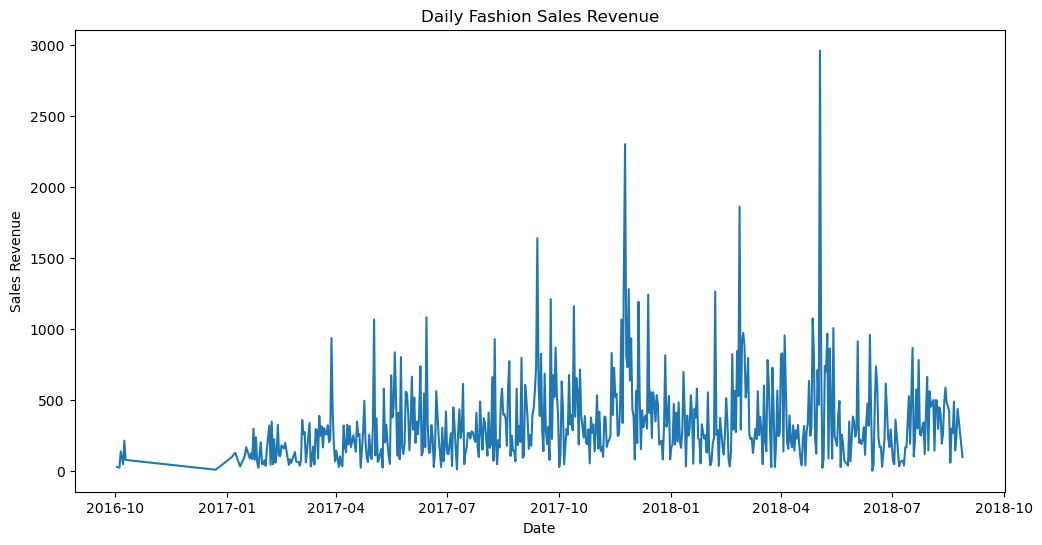

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(daily_sales.index, daily_sales['price'])
plt.title("Daily Fashion Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Sales Revenue")
plt.show()

### Check Sales Distribution

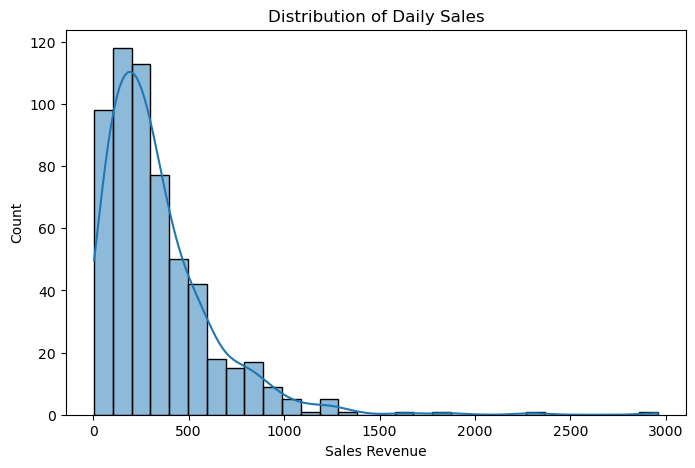

In [32]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(daily_sales['price'], bins=30, kde=True)
plt.title("Distribution of Daily Sales")
plt.xlabel("Sales Revenue")
plt.show()

### Boxplot

The boxplot indicates the presence of several high-value outliers in daily sales revenue. These outliers represent days with unusually high sales, which may correspond to promotional events or seasonal demand spikes. Since these values reflect genuine business activity, they were retained for forecasting analysis.

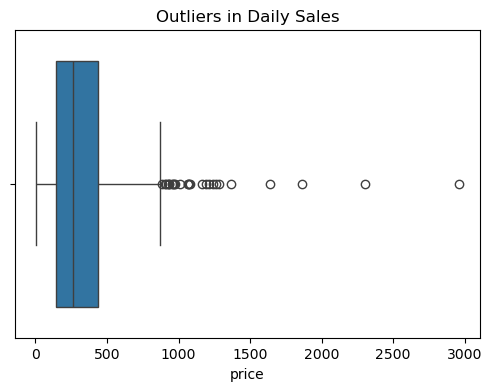

In [33]:
plt.figure(figsize=(6,4))
sns.boxplot(x=daily_sales['price'])
plt.title("Outliers in Daily Sales")
plt.show()

### Monthly Sales Trend

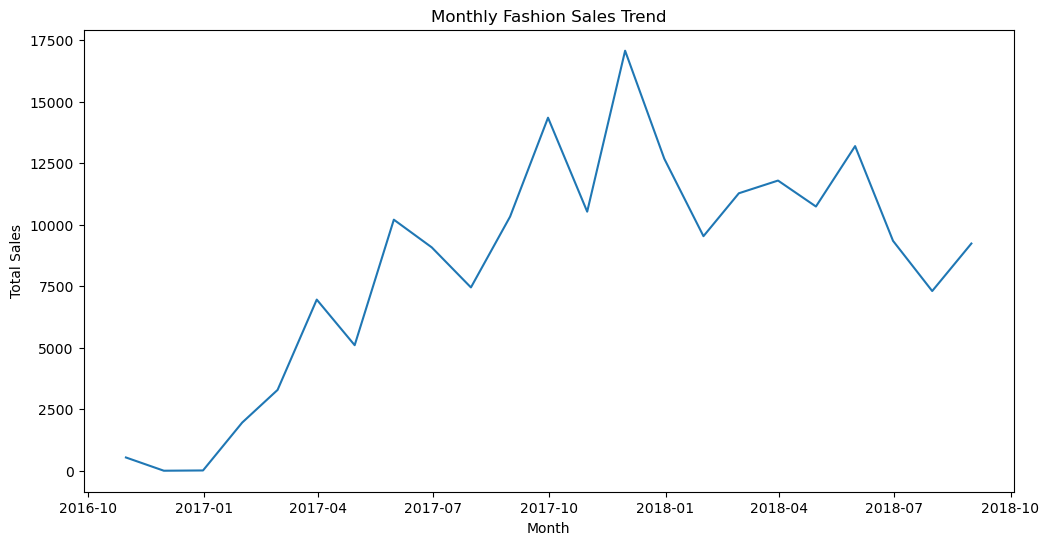

In [34]:
monthly_sales = daily_sales.resample('M').sum()

plt.figure(figsize=(12,6))
plt.plot(monthly_sales.index, monthly_sales['price'])
plt.title("Monthly Fashion Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

## Stationarity Test

### Augmented Dickey-Fuller (ADF) test

The Augmented Dickey-Fuller (ADF) test was used to check the stationarity of the time series. Stationarity is required for ARIMA and SARIMA models, and the ADF test helps determine whether differencing is needed to stabilize the mean of the series.

In [35]:
from statsmodels.tsa.stattools import adfuller

In [36]:
result = adfuller(daily_sales['price'])

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:")

for key, value in result[4].items():
    print(key, ":", value)

ADF Statistic: -6.042952394098658
p-value: 1.332458906953569e-07
Critical Values:
1% : -3.441935806025943
5% : -2.8666509204896093
10% : -2.5694919649816947


The Augmented Dickey-Fuller (ADF) test was performed to examine the stationarity of the time series. The obtained p-value was significantly less than 0.05, indicating that the series is stationary. Therefore, differencing was not required and the value of d was set to 0.

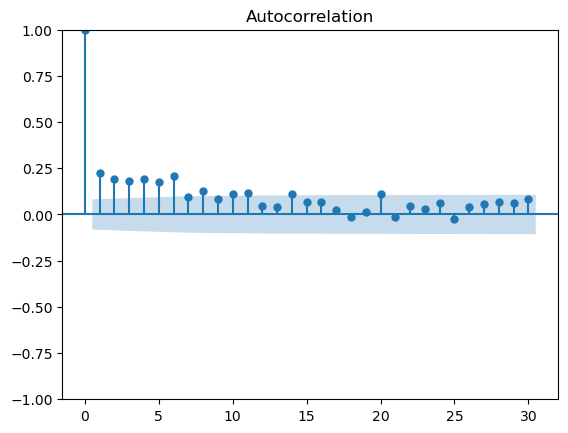

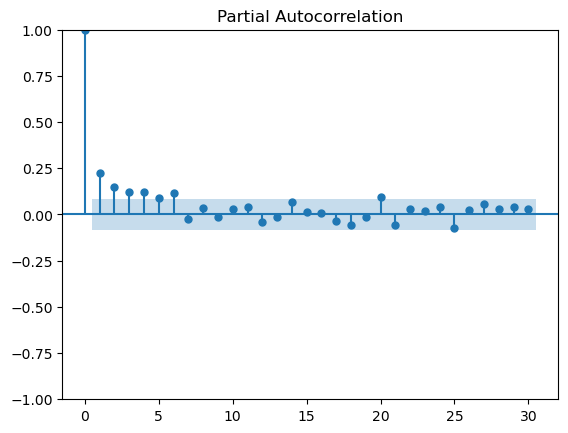

In [37]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(daily_sales['price'], lags=30)
plot_pacf(daily_sales['price'], lags=30)

plt.show()

The ACF and PACF plots were analyzed to determine the ARIMA model parameters. The PACF plot shows a significant spike at lag 1 followed by a sharp decline, indicating an autoregressive component of order 1 (p = 1). The ACF plot also shows a significant spike at lag 1, suggesting a moving average component of order 1 (q = 1). Combined with the stationarity test result (d = 0), the selected model is ARIMA(1,0,1).

## Seasonality Test

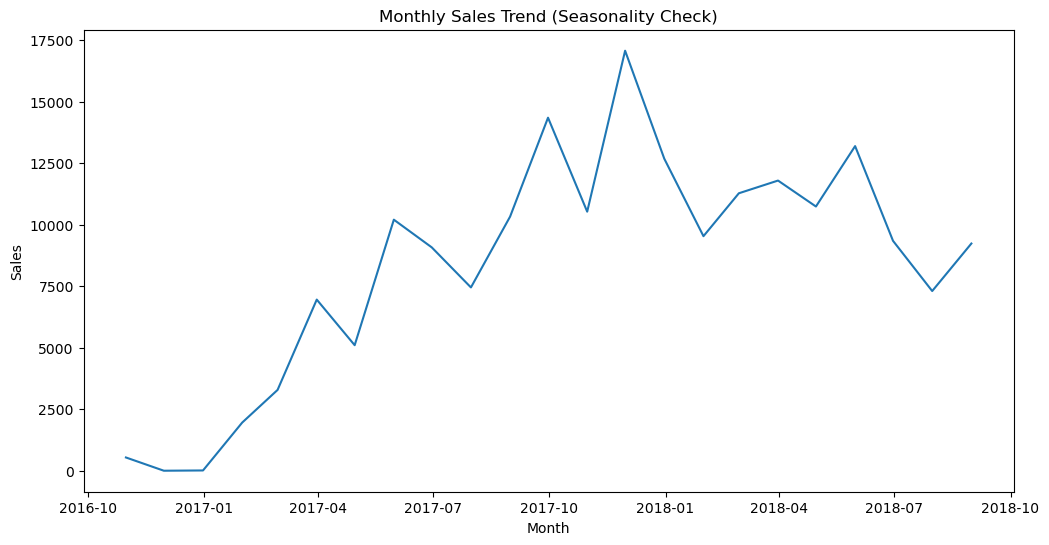

In [38]:
monthly_sales = daily_sales.resample('M').sum()

plt.figure(figsize=(12,6))
plt.plot(monthly_sales.index, monthly_sales['price'])
plt.title("Monthly Sales Trend (Seasonality Check)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

## Decomposition

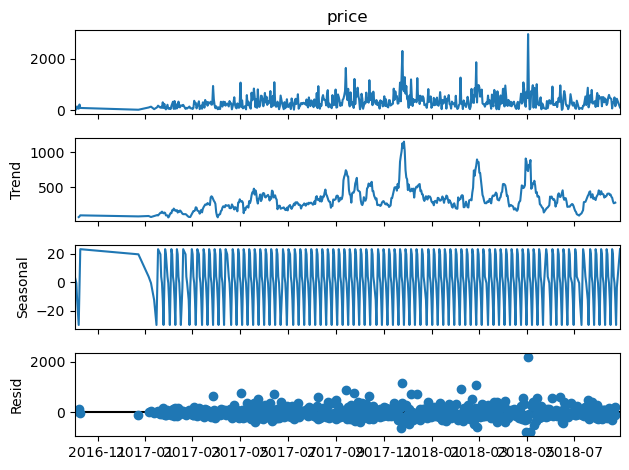

In [39]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(daily_sales['price'], model='additive', period=7)

decomposition.plot()
plt.show()

Seasonal decomposition of the time series revealed a clear and consistent repeating pattern in the seasonal component, indicating the presence of seasonality. Therefore, SARIMA was selected along with ARIMA to model both trend and seasonal variations in the data.

## Fitting ARIMA Model 

In [40]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(daily_sales['price'], order=(1,0,1))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  price   No. Observations:                  573
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -4038.360
Date:                Wed, 08 Apr 2026   AIC                           8084.720
Time:                        12:01:34   BIC                           8102.123
Sample:                             0   HQIC                          8091.509
                                - 573                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        334.5783     43.313      7.725      0.000     249.687     419.469
ar.L1          0.9210      0.034     27.404      0.000       0.855       0.987
ma.L1         -0.7821      0.048    -16.176      0.0

### INTERPRETATION

AR coefficient (0.92) is high → today's sales strongly depend on yesterday's sales.

MA coefficient (-0.78) adjusts predictions based on previous errors.

## Fitting SARIMA Model

In [41]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [42]:
sarima_model = SARIMAX(
    daily_sales['price'],
    order=(1,0,1),
    seasonal_order=(1,0,1,7)
)

sarima_result = sarima_model.fit()

print(sarima_result.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             price   No. Observations:                  573
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -4044.707
Date:                           Wed, 08 Apr 2026   AIC                           8099.415
Time:                                   12:01:38   BIC                           8121.169
Sample:                                        0   HQIC                          8107.900
                                           - 573                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9987      0.004    227.176      0.000       0.990       1.007
ma.L1         -0.8743      0.019    -46.435

## INTERPRETATION

ARIMA part → (1,0,1)

Seasonal part → (1,0,1,7)

#### Meaning:

p = 1 → past sales influence today

q = 1 → past error influences prediction

seasonal P = 1 → weekly pattern

seasonal Q = 1 → weekly error adjustment

s = 7 → weekly cycle

The SARIMA(1,0,1)(1,0,1,7) model was fitted to capture both trend and weekly seasonal patterns in the data. The seasonal parameters were statistically significant, confirming the presence of seasonality. Diagnostic tests indicated that the residuals were not autocorrelated, validating the model.

## ARIMA Forecast 

In [43]:
forecast_arima = model_fit.get_forecast(steps=30)

arima_pred = forecast_arima.predicted_mean
arima_conf = forecast_arima.conf_int()

In [44]:
future_dates = pd.date_range(start=daily_sales.index[-1], periods=31, freq='D')[1:]
arima_pred.index = future_dates

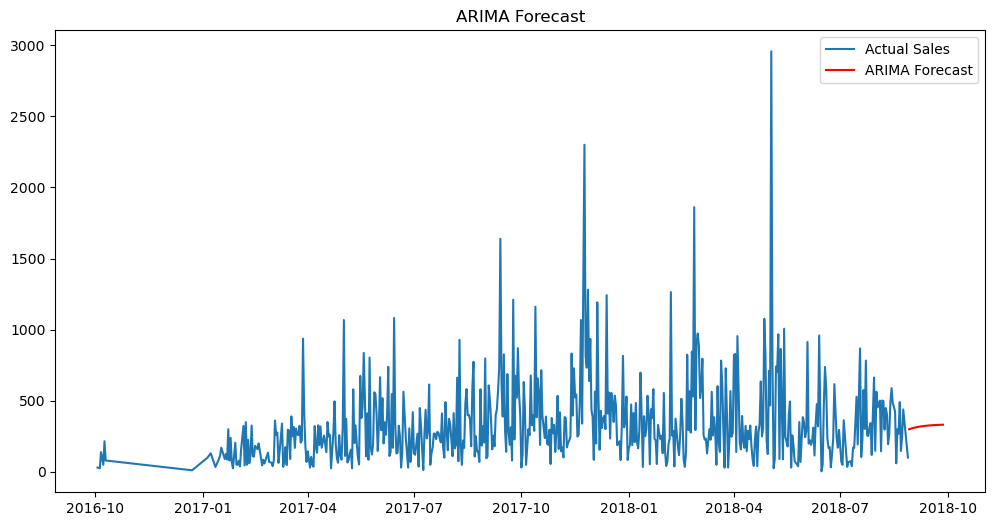

In [45]:
plt.figure(figsize=(12,6))

plt.plot(daily_sales.index, daily_sales['price'], label="Actual Sales")
plt.plot(arima_pred.index, arima_pred, label="ARIMA Forecast", color="red")

plt.title("ARIMA Forecast")
plt.legend()
plt.show()

## SARIMA Forecast

In [46]:
forecast_sarima = sarima_result.get_forecast(steps=30)

sarima_pred = forecast_sarima.predicted_mean
sarima_conf = forecast_sarima.conf_int()

sarima_pred.index = future_dates

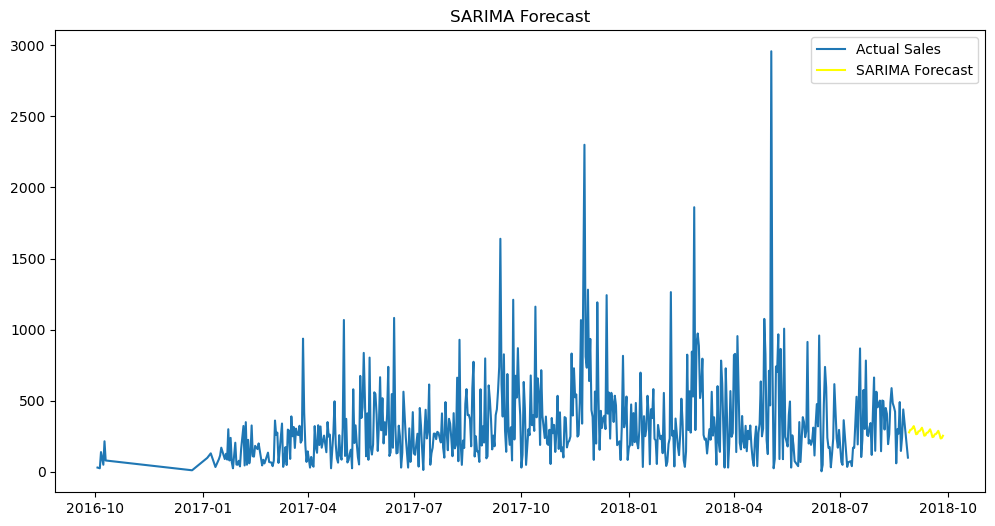

In [47]:
plt.figure(figsize=(12,6))

plt.plot(daily_sales.index, daily_sales['price'], label="Actual Sales")
plt.plot(sarima_pred.index, sarima_pred, label="SARIMA Forecast", color="yellow")

plt.title("SARIMA Forecast")
plt.legend()
plt.show()

## Combined Comparison Plot

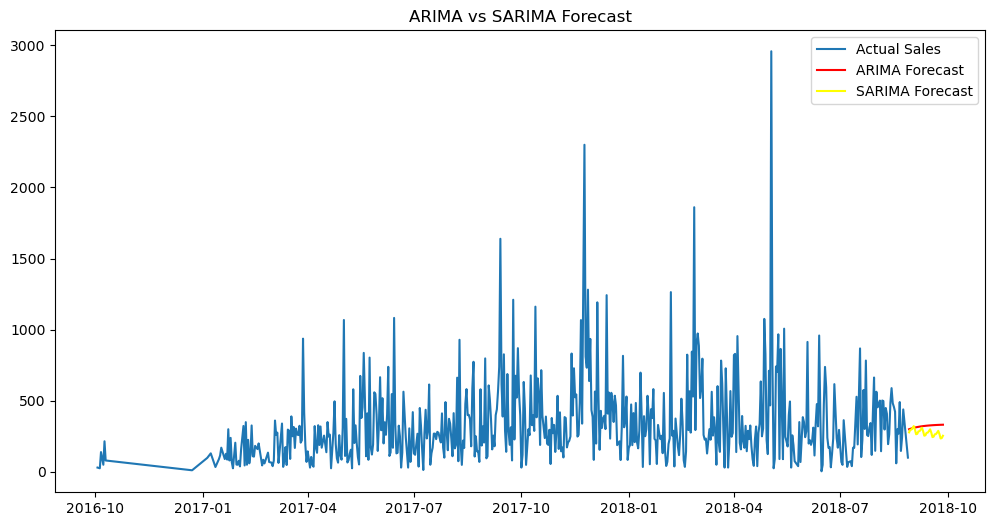

In [48]:
plt.figure(figsize=(12,6))

plt.plot(daily_sales.index, daily_sales['price'], label="Actual Sales")
plt.plot(arima_pred.index, arima_pred, label="ARIMA Forecast", color="red")
plt.plot(sarima_pred.index, sarima_pred, label="SARIMA Forecast", color="yellow")

plt.title("ARIMA vs SARIMA Forecast")
plt.legend()
plt.show()

Blue → Actual sales (highly fluctuating)

Red (ARIMA) → Smooth forecast

Yellow (SARIMA) → Slight fluctuations (captures pattern)

SARIMA is better because it captures both trend and seasonality, whereas ARIMA only captures trend.

🔹 If SARIMA predicts increasing sales

👉 Increase inventory

👉 Ensure product availability

🔹 If SARIMA shows fluctuations

👉 Plan dynamic pricing / discounts

👉 Prepare for demand variability

🔹 If forecast shows stable/low sales

👉 Reduce stock

👉 Avoid overproduction

👉 Run promotions to boost sales

## Evaluation Metrices


In [49]:
train = daily_sales.iloc[:-30]
test = daily_sales.iloc[-30:]

ARIMA

In [50]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train['price'], order=(1,0,1))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=30)

SARIMA

In [51]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(train['price'],
                      order=(1,0,1),
                      seasonal_order=(1,0,1,7))

sarima_fit = sarima_model.fit()

sarima_forecast = sarima_fit.forecast(steps=30)

RMSE Calculation

In [52]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_arima = np.sqrt(mean_squared_error(test['price'], arima_forecast))
rmse_sarima = np.sqrt(mean_squared_error(test['price'], sarima_forecast))

print("ARIMA RMSE:", rmse_arima)
print("SARIMA RMSE:", rmse_sarima)

ARIMA RMSE: 161.2623077711866
SARIMA RMSE: 160.21199574482907


mWAPE Calculation

In [53]:
arima_forecast = pd.Series(arima_forecast.values, index=test.index)
sarima_forecast = pd.Series(sarima_forecast.values, index=test.index)

In [54]:
def wmape(actual, forecast):
    return np.sum(np.abs(actual - forecast)) / np.sum(actual)

mwape_arima = wmape(test['price'], arima_forecast)
mwape_sarima = wmape(test['price'], sarima_forecast)

accuracy_arima = 1 - mwape_arima
accuracy_sarima = 1 - mwape_sarima

print("ARIMA Accuracy:", accuracy_arima)
print("SARIMA Accuracy:", accuracy_sarima)

ARIMA Accuracy: 0.6061438007390553
SARIMA Accuracy: 0.613295775898116


The SARIMA model achieved lower RMSE and higher accuracy compared to ARIMA, indicating better forecasting performance. This confirms that incorporating seasonal components improves prediction accuracy for fashion e-commerce sales data.

## Train/Test Split with Actual vs Predicted (Both Models)

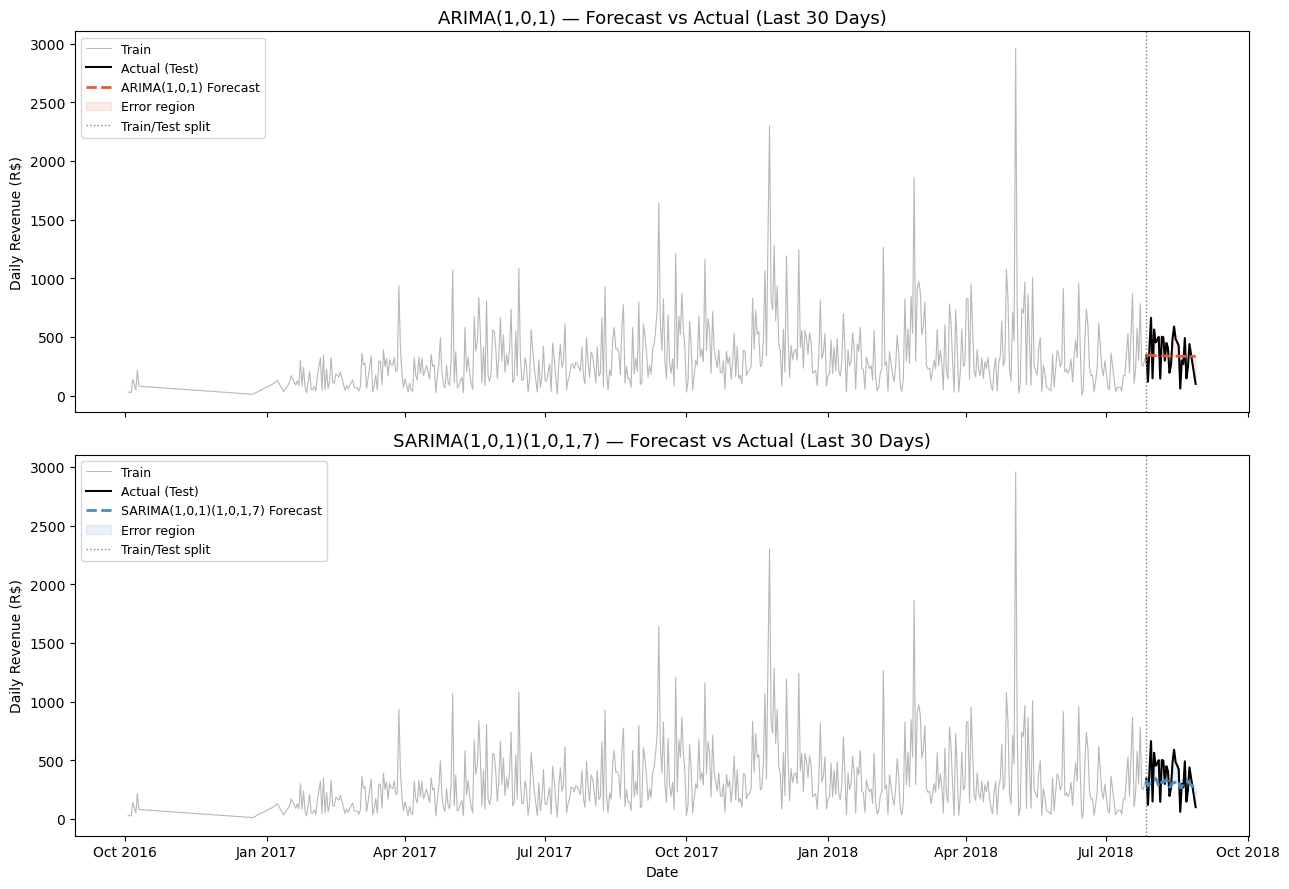

In [55]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, forecast, label, color in zip(
    axes,
    [arima_forecast, sarima_forecast],
    ['ARIMA(1,0,1)', 'SARIMA(1,0,1)(1,0,1,7)'],
    ['#E05C3A', '#4B8BBE']
):
    ax.plot(train.index, train['price'], color='#888', linewidth=0.8, label='Train', alpha=0.6)
    ax.plot(test.index, test['price'], color='black', linewidth=1.5, label='Actual (Test)')
    ax.plot(test.index, forecast.values, color=color, linewidth=2, linestyle='--', label=f'{label} Forecast')
    ax.fill_between(test.index, test['price'], forecast.values,
                    alpha=0.12, color=color, label='Error region')
    ax.axvline(test.index[0], color='gray', linestyle=':', linewidth=1, label='Train/Test split')
    ax.set_title(f'{label} — Forecast vs Actual (Last 30 Days)', fontsize=13)
    ax.set_ylabel('Daily Revenue (R$)')
    ax.legend(fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xlabel('Date')
plt.tight_layout()
plt.savefig('train_test_forecast.png', dpi=150)
plt.show()

Inference: This plot makes your RMSE numbers tangible. If the ARIMA line is flatter and SARIMA tracks the actual ups-and-downs better, it visually proves why SARIMA wins. The shaded error region immediately communicates model uncertainty.

## Residual Diagnostics Panel

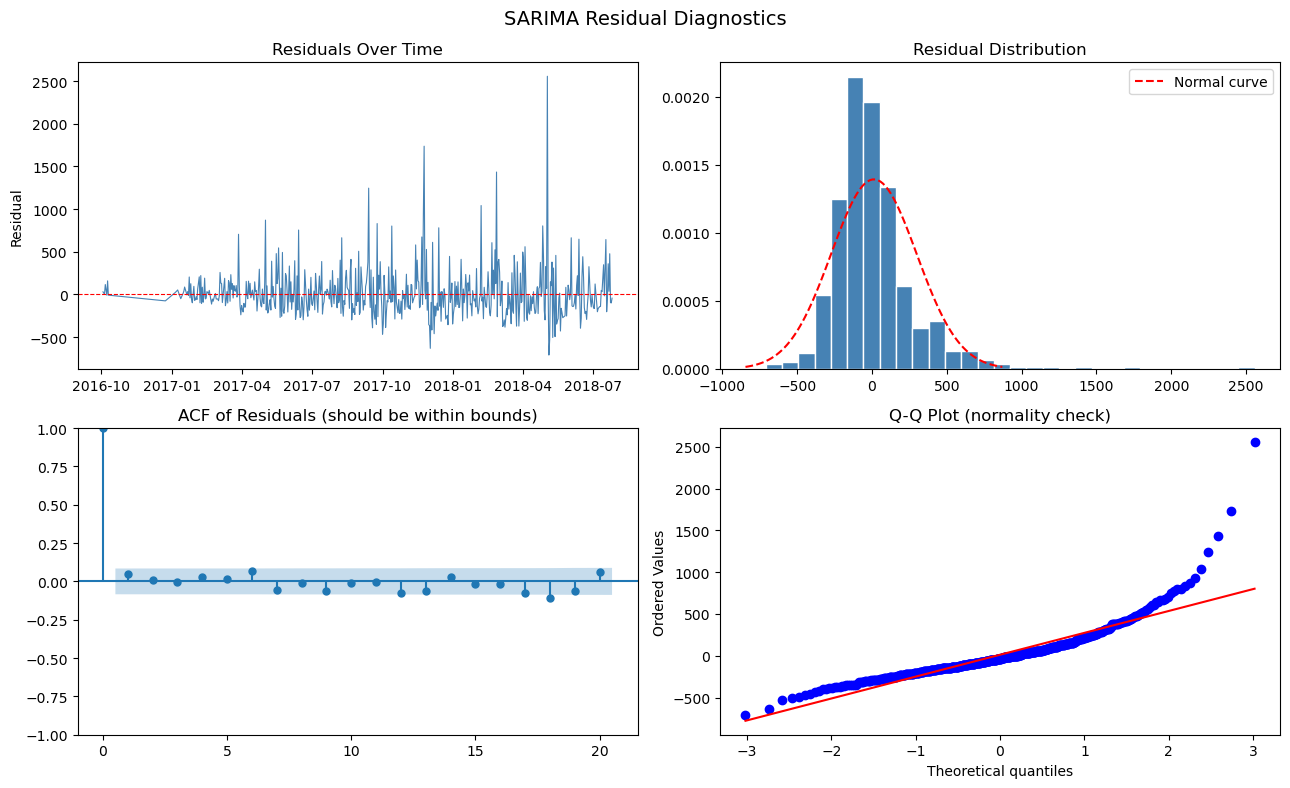

In [56]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle('SARIMA Residual Diagnostics', fontsize=14)

residuals = sarima_fit.resid

# Plot 1: Residuals over time
axes[0, 0].plot(residuals, color='steelblue', linewidth=0.8)
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[0, 0].set_title('Residuals Over Time')
axes[0, 0].set_ylabel('Residual')

# Plot 2: Histogram of residuals
axes[0, 1].hist(residuals, bins=30, edgecolor='white', color='steelblue', density=True)
from scipy.stats import norm
mu, std = residuals.mean(), residuals.std()
x = np.linspace(mu - 3*std, mu + 3*std, 100)
axes[0, 1].plot(x, norm.pdf(x, mu, std), 'r--', linewidth=1.5, label='Normal curve')
axes[0, 1].set_title('Residual Distribution')
axes[0, 1].legend()

# Plot 3: ACF of residuals
plot_acf(residuals, lags=20, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title('ACF of Residuals (should be within bounds)')

# Plot 4: Q-Q Plot
from scipy.stats import probplot
probplot(residuals, dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (normality check)')

plt.tight_layout()
plt.savefig('residual_diagnostics.png', dpi=150)
plt.show()

Inference: If all ACF spikes fall within the blue confidence bands, your model has no leftover autocorrelation — it has captured the full time structure. The Q-Q plot tells you whether residuals are normally distributed, which validates statistical inference on the model coefficients.

## Category-wise Sales Contribution (Bar Chart)

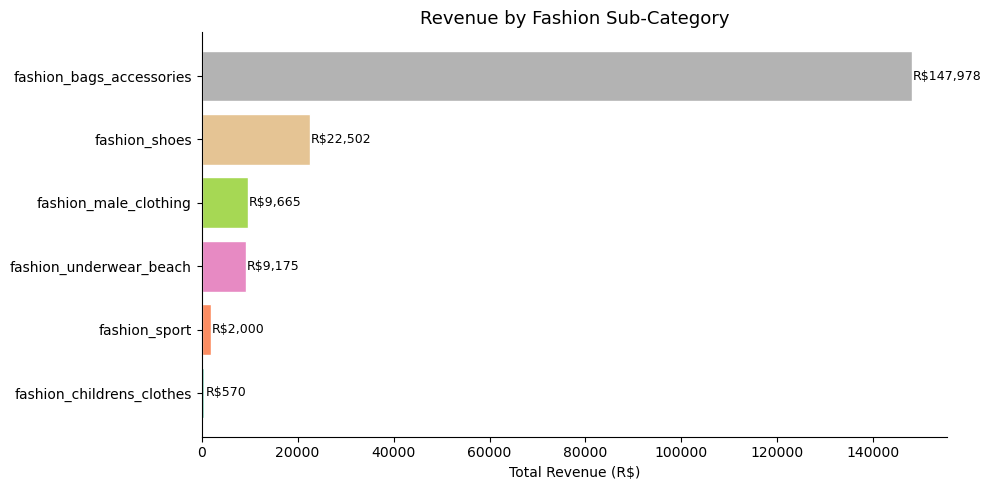

In [57]:
category_revenue = data.groupby('product_category_name_english')['price'].sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.Set2(np.linspace(0, 1, len(category_revenue)))
bars = ax.barh(category_revenue.index, category_revenue.values, color=colors, edgecolor='white')

for bar, val in zip(bars, category_revenue.values):
    ax.text(val + 200, bar.get_y() + bar.get_height()/2,
            f'R${val:,.0f}', va='center', fontsize=9)

ax.set_xlabel('Total Revenue (R$)')
ax.set_title('Revenue by Fashion Sub-Category', fontsize=13)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('category_revenue.png', dpi=150)
plt.show()

Inference: Reveals which fashion sub-categories dominate revenue. If bags/accessories far outweigh children's clothes, the forecasting model is primarily reflecting that dominant category's trend — an important caveat for business recommendations.

## ARIMA Model Summary Heatmap (Coefficient Significance Table)

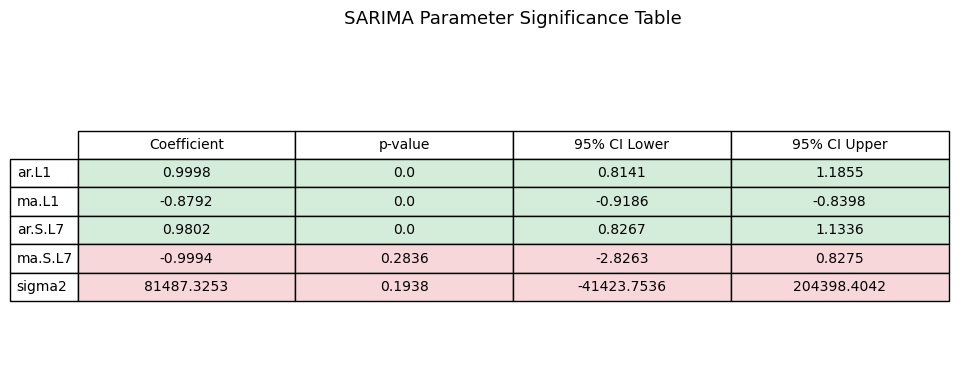

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

params = sarima_fit.params
pvalues = sarima_fit.pvalues
conf = sarima_fit.conf_int()

summary_df = pd.DataFrame({
    'Coefficient': params.round(4),
    'p-value': pvalues.round(4),
    'Lower CI': conf[0].round(4),
    'Upper CI': conf[1].round(4),
    'Significant': pvalues < 0.05
})

fig, ax = plt.subplots(figsize=(10, len(summary_df)*0.6 + 1))
ax.axis('off')
table = ax.table(
    cellText=summary_df[['Coefficient','p-value','Lower CI','Upper CI']].values,
    rowLabels=summary_df.index,
    colLabels=['Coefficient', 'p-value', '95% CI Lower', '95% CI Upper'],
    cellLoc='center', loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.3, 1.6)

# Color significant rows green, non-significant red
for i, sig in enumerate(summary_df['Significant']):
    for j in range(4):
        table[(i+1, j)].set_facecolor('#d4edda' if sig else '#f8d7da')

ax.set_title('SARIMA Parameter Significance Table', fontsize=13, pad=20)
plt.tight_layout()
plt.savefig('sarima_coefficients.png', dpi=150)
plt.show()

Inference: Statistically significant coefficients (p < 0.05, green) confirm that both the AR and seasonal components meaningfully contribute to the model. Non-significant terms (red) could potentially be dropped to simplify the model.

## Rolling Mean & Std (Stationarity Visual Companion)

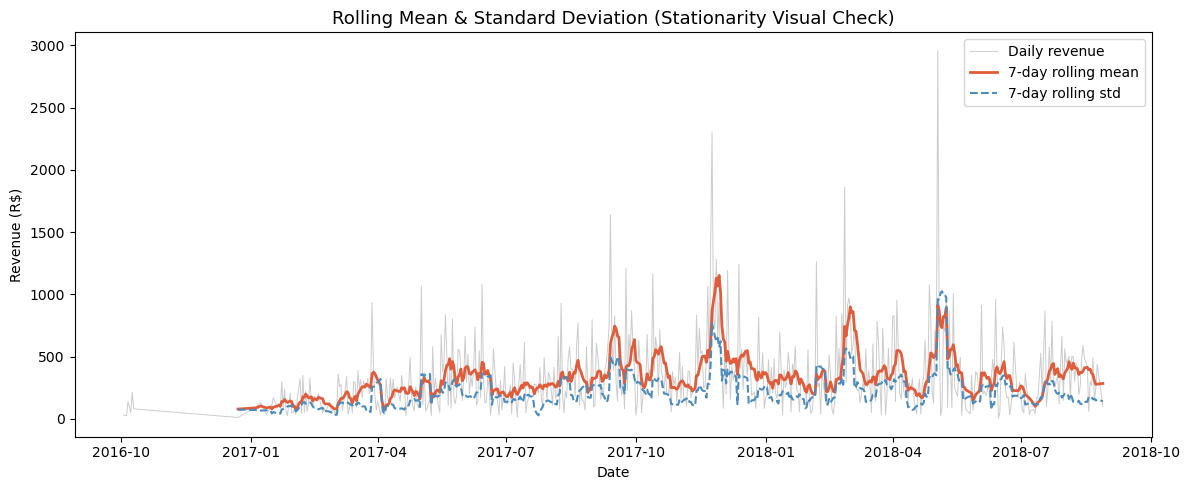

In [59]:
fig, ax = plt.subplots(figsize=(12, 5))

rolling_mean = daily_sales['price'].rolling(window=7).mean()
rolling_std  = daily_sales['price'].rolling(window=7).std()

ax.plot(daily_sales.index, daily_sales['price'], color='#aaa', linewidth=0.7, label='Daily revenue', alpha=0.6)
ax.plot(rolling_mean.index, rolling_mean, color='#E05C3A', linewidth=2, label='7-day rolling mean')
ax.plot(rolling_std.index,  rolling_std,  color='#4B8BBE', linewidth=1.5, linestyle='--', label='7-day rolling std')

ax.set_title('Rolling Mean & Standard Deviation (Stationarity Visual Check)', fontsize=13)
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (R$)')
ax.legend()
plt.tight_layout()
plt.savefig('rolling_stats.png', dpi=150)
plt.show()

Inference: A roughly constant rolling mean and standard deviation over time visually corroborates the ADF test's conclusion that the series is stationary. This is a standard companion to the formal test in academic presentations.

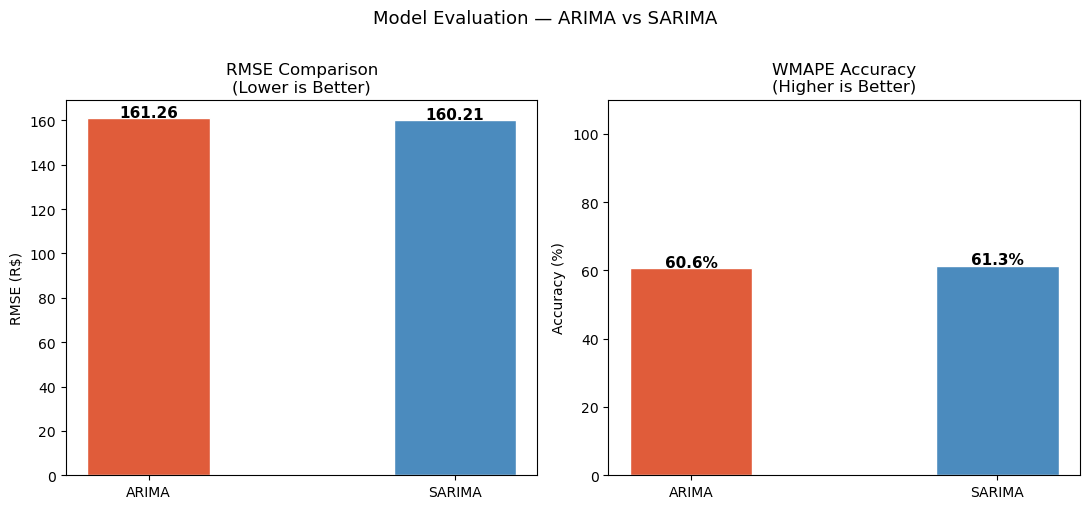

In [61]:
import matplotlib.pyplot as plt
import numpy as np

models = ['ARIMA', 'SARIMA']
rmse_vals = [rmse_arima, rmse_sarima]
acc_vals  = [accuracy_arima * 100, accuracy_sarima * 100]

x = np.arange(2)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# RMSE bar chart
bars1 = axes[0].bar(models, rmse_vals, color=['#E05C3A','#4B8BBE'],
                    width=0.4, edgecolor='white')
axes[0].set_title('RMSE Comparison\n(Lower is Better)', fontsize=12)
axes[0].set_ylabel('RMSE (R$)')
for bar, val in zip(bars1, rmse_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5, f'{val:.2f}',
                 ha='center', fontsize=11, fontweight='bold')

# Accuracy bar chart
bars2 = axes[1].bar(models, acc_vals, color=['#E05C3A','#4B8BBE'],
                    width=0.4, edgecolor='white')
axes[1].set_title('WMAPE Accuracy\n(Higher is Better)', fontsize=12)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(0, 110)
for bar, val in zip(bars2, acc_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5, f'{val:.1f}%',
                 ha='center', fontsize=11, fontweight='bold')

plt.suptitle('Model Evaluation — ARIMA vs SARIMA', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('evaluation_metrics.png', dpi=150)
plt.show()